In [ ]:
# CELL 1 — Setup

import pandas as pd
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, mean_absolute_error

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
SEQ_LEN    = 20       # timesteps per window
BATCH_SIZE = 64
EPOCHS     = 20
LR         = 1e-3

feature_cols = ['vibration_rms','temperature_motor','current_phase_avg',
                'pressure_level','rpm','operating_mode_enc',
                'hours_since_maintenance']

In [ ]:
# CELL 2 — Load & Preprocess

df = pd.read_csv(r"E:\DOCUMENTS\UNIVERSITÄT STUTTGART\SEMESTER COURSES\7. WiSe 2025-26\RP\Datasets\predictive_maintenance_v03.csv")
df['timestamp'] = pd.to_datetime(df['timestamp'])
df = df.sort_values(['machine_id','timestamp']).reset_index(drop=True)

df['operating_mode_enc'] = df['operating_mode'].map({'idle':0,'normal':1,'peak':2})
df['failure_label'] = df['failure_type'].map(
    {'none':0,'hydraulic':1,'bearing':2,'motor_overheat':3,'electrical':4}
)
# Adding this after the map to catch silent losses ************

print(df['failure_label'].value_counts(dropna=False))
# Check: are electrical(4) and motor_overheat(3) actually present?
df[feature_cols] = df.groupby('machine_id')[feature_cols].transform(
    lambda x: x.ffill().fillna(x.mean())
)
df = df.dropna(subset=feature_cols+['failure_label','rul_hours']).reset_index(drop=True)

failure_label
0    20482
2     1117
3     1060
1      728
4      655
Name: count, dtype: int64


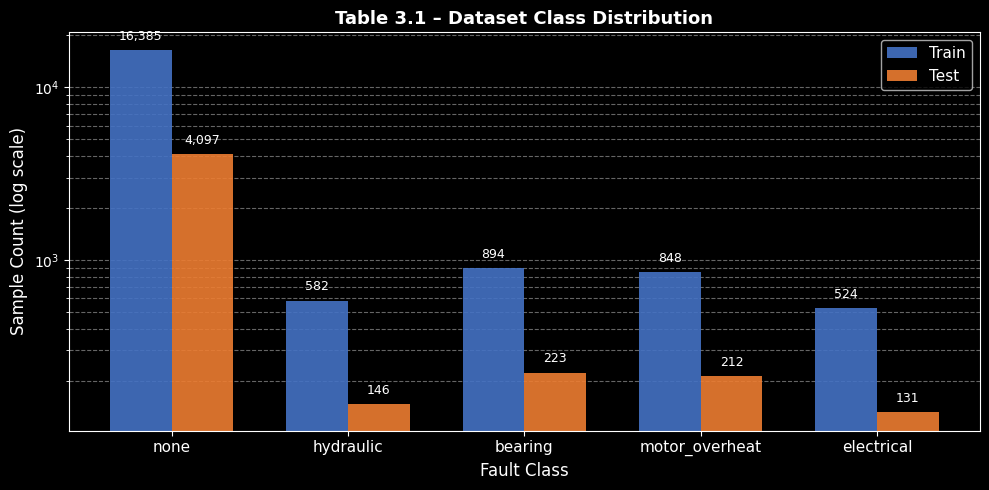

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split

# Build train/test split from my df ***********

train_df, test_df = train_test_split(
    df, test_size=0.2, random_state=42,
    stratify=df['failure_type']          # It keeps class ratios in both splits
)

class_order  = ['none', 'hydraulic', 'bearing', 'motor_overheat', 'electrical']
train_counts = [train_df['failure_type'].value_counts().get(c, 0) for c in class_order]
test_counts  = [ test_df['failure_type'].value_counts().get(c, 0) for c in class_order]

# Plot **************

x, w = np.arange(len(class_order)), 0.35

fig, ax = plt.subplots(figsize=(10, 5))
b1 = ax.bar(x - w/2, train_counts, w, label='Train', color='#4472C4', alpha=0.9)
b2 = ax.bar(x + w/2, test_counts,  w, label='Test',  color='#ED7D31', alpha=0.9)

for bar, v in zip(b1, train_counts):
    ax.text(bar.get_x() + w/2, bar.get_height()*1.1, f'{v:,}',
            ha='center', va='bottom', fontsize=9)
for bar, v in zip(b2, test_counts):
    ax.text(bar.get_x() + w/2, bar.get_height()*1.1, f'{v:,}',
            ha='center', va='bottom', fontsize=9)

ax.set_yscale('log')
ax.set_xticks(x)
ax.set_xticklabels(class_order, fontsize=11)
ax.set_xlabel('Fault Class', fontsize=12)
ax.set_ylabel('Sample Count (log scale)', fontsize=12)
ax.set_title('Table 3.1 – Dataset Class Distribution', fontsize=13, fontweight='bold')
ax.legend(fontsize=11)
ax.yaxis.grid(True, which='both', linestyle='--', alpha=0.4)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig('class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
# CELL 3 — Sliding Window Dataset

class SlidingWindowDataset(Dataset):
    def __init__(self, df, seq_len, task='classification'):
        self.X, self.y = [], []
        for mid, grp in df.groupby('machine_id'):
            grp = grp.sort_values('timestamp').reset_index(drop=True)
            X_arr = grp[feature_cols].values.astype(np.float32)
            y_arr = (grp['failure_label'].values.astype(np.int64)
                     if task == 'classification'
                     else grp['rul_hours'].values.astype(np.float32))
            for i in range(len(grp) - seq_len):
                self.X.append(X_arr[i : i + seq_len])
                self.y.append(y_arr[i + seq_len-1])                    # label at the end of the window
        self.X = torch.tensor(np.array(self.X))
        self.y = torch.tensor(np.array(self.y))

    def __len__(self):  return len(self.X)
    def __getitem__(self, i): return self.X[i], self.y[i]

In [ ]:
# CELL 4 — Train/Test Split + Dataloaders

# Temporal split per machine **************************

train_dfs, test_dfs = [], []
RARE_FAULTS = ['motor_overheat', 'electrical']
for mid, grp in df.groupby('machine_id'):
    grp = grp.reset_index(drop=True)
    rare_fault_indices = grp[grp['failure_type'].isin(RARE_FAULTS)].index.tolist()
    
    if rare_fault_indices:
        # Cut at 80th percentile of fault positions so that the last 20% of faults go to test **************
        fault_cutoff = int(np.percentile(rare_fault_indices, 80))
        cutoff = max(fault_cutoff, int(len(grp) * 0.5))                 # min 50% for train
    else:
        cutoff = int(len(grp) * 0.8)                     # default for machines without rare faults
    
    train_dfs.append(grp.iloc[:cutoff])
    test_dfs.append(grp.iloc[cutoff:])

train_df = pd.concat(train_dfs).reset_index(drop=True)
test_df  = pd.concat(test_dfs).reset_index(drop=True)


# scalar should be fit only on training data to avoid data leakage ************
scaler = StandardScaler()
train_df[feature_cols] = scaler.fit_transform(train_df[feature_cols])
test_df[feature_cols]  = scaler.transform(test_df[feature_cols])            # when no fit


# Classification loaders **********

train_cls = DataLoader(SlidingWindowDataset(train_df, SEQ_LEN, 'classification'),
                       batch_size=BATCH_SIZE, shuffle=True)
test_cls  = DataLoader(SlidingWindowDataset(test_df,  SEQ_LEN, 'classification'),
                       batch_size=BATCH_SIZE, shuffle=False)

# Regression loaders ************

train_reg = DataLoader(SlidingWindowDataset(train_df, SEQ_LEN, 'regression'),
                       batch_size=BATCH_SIZE, shuffle=True)
test_reg  = DataLoader(SlidingWindowDataset(test_df,  SEQ_LEN, 'regression'),
                       batch_size=BATCH_SIZE, shuffle=False)

print(f"Train batches: {len(train_cls)} | Test batches: {len(test_cls)}")

Train batches: 251 | Test batches: 113


In [ ]:
# CELL 5 — LSTM Model Definition

class LSTMModel(nn.Module):
    def __init__(self, input_size, hidden_size, num_layers, output_size, dropout=0.3):
        super().__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers,
                            batch_first=True, dropout=dropout)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        out, _ = self.lstm(x)
        out = self.dropout(out[:, -1, :])           # it saves last timestep only
        return self.fc(out)

In [ ]:
class FocalLoss(nn.Module):
    def __init__(self, weight=None, gamma=2.0):
        super().__init__()
        self.weight = weight          # class weights (same as CrossEntropyLoss)
        self.gamma  = gamma           # focusing parameter — higher = more focus on hard classes

    def forward(self, preds, targets):
        ce_loss = nn.functional.cross_entropy(preds, targets, weight=self.weight, reduction='none')
        pt      = torch.exp(-ce_loss)                    # probability of correct class
        focal   = (1 - pt) ** self.gamma * ce_loss           # down-weight easy, up-weight hard
        return focal.mean()

In [ ]:
# CELL 6 — Train Classification (Fault Type)

import copy
cls_model = LSTMModel(
    input_size=len(feature_cols),
    hidden_size=128,
    num_layers=2,
    output_size=5,                      # 5 failure classes ********
    dropout=0.3
).to(DEVICE)

#  compute inverse-frequency weights from your training dataset

from collections import Counter

label_counts = Counter(train_cls.dataset.y.numpy())       # counts per class ******
total = sum(label_counts.values())
weights = torch.tensor(
    [total / (5 * label_counts.get(i, 1)) for i in range(5)],
    dtype=torch.float32
).to(DEVICE)

print("Class weights:", weights)           # verify rare classes get higher weight
criterion_cls = FocalLoss(weight=weights, gamma=2.0)

optimizer_cls = torch.optim.Adam(cls_model.parameters(), lr=LR)

# Add scheduler after optimizer definition  ****************

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_cls,
    mode='min',               # reduce when loss stops decreasing
    factor=0.99,              # multiply LR by 0.5 when triggered
    patience=5,               # wait 3 epochs of no improvement before reducing
    min_lr=1e-4,               # never go below this
)
min_loss=1000
for epoch in range(EPOCHS):
    cls_model.train()
    total_loss = 0
    for X_batch, y_batch in train_cls:
        X_batch, y_batch = X_batch.to(DEVICE), y_batch.to(DEVICE)
        optimizer_cls.zero_grad()
        preds = cls_model(X_batch)
        loss  = criterion_cls(preds, y_batch)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(cls_model.parameters(), max_norm=1.0) 
        optimizer_cls.step()
        total_loss += loss.item()

    avg_loss = total_loss / len(train_cls)
    scheduler.step(avg_loss)                 # add at end of each epoch ******
    if (epoch+1) % 10 == 0:
        print(f"Epoch {epoch+1}/{EPOCHS} | Loss: {total_loss/len(train_cls):.4f}")

# Evaluation ********************** 

cls_model.eval()
all_preds, all_labels = [], []
with torch.no_grad():
    for X_batch, y_batch in test_cls:
        preds = cls_model(X_batch.to(DEVICE)).argmax(dim=1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(y_batch.numpy())

print("\n=== LSTM Fault Classification Report ===")
labels = [0, 1, 2, 3, 4]
target_names = ['none', 'hydraulic', 'bearing', 'motor_overheat', 'electrical']
print(classification_report(all_labels, all_preds, labels=labels, target_names=target_names, zero_division=0))



Class weights: tensor([0.2422, 5.8301, 4.1828, 3.6176, 5.4264])
Epoch 10/20 | Loss: 0.0125
Epoch 20/20 | Loss: 0.0098

=== LSTM Fault Classification Report ===
                precision    recall  f1-score   support

          none       0.99      0.97      0.98      6579
     hydraulic       0.39      0.57      0.46       157
       bearing       0.73      0.87      0.80       349
motor_overheat       0.89      1.00      0.94        72
    electrical       0.43      1.00      0.60        23

      accuracy                           0.95      7180
     macro avg       0.69      0.88      0.76      7180
  weighted avg       0.97      0.95      0.96      7180



In [ ]:
# CELL 7 — Train RUL Regression

reg_model = LSTMModel(
    input_size=len(feature_cols),
    hidden_size=64,
    num_layers=2,
    output_size=1,           # single RUL value
    dropout=0.3
).to(DEVICE)

criterion_reg = nn.MSELoss()
optimizer_reg = torch.optim.Adam(reg_model.parameters(), lr=LR)

for epoch in range(EPOCHS):
    reg_model.train()
    total_loss = 0
    for X_batch, y_batch in train_reg:
        X_batch = X_batch.to(DEVICE)
        y_batch = y_batch.unsqueeze(1).to(DEVICE)
        optimizer_reg.zero_grad()
        preds = reg_model(X_batch)
        loss  = criterion_reg(preds, y_batch)
        loss.backward()
        optimizer_reg.step()
        total_loss += loss.item()
    if (epoch+1) % 5 == 0:
        print(f"Epoch {epoch+1}/{EPOCHS} | MSE Loss: {total_loss/len(train_reg):.4f}")

# Evaluation *********

reg_model.eval()
all_preds_r, all_labels_r = [], []
with torch.no_grad():
    for X_batch, y_batch in test_reg:
        preds = reg_model(X_batch.to(DEVICE)).squeeze().cpu().numpy()
        all_preds_r.extend(np.atleast_1d(preds).tolist())
        all_labels_r.extend(y_batch.numpy())

mae  = mean_absolute_error(all_labels_r, all_preds_r)
rmse = np.sqrt(np.mean((np.array(all_labels_r) - np.array(all_preds_r))**2))
print(f"\n=== LSTM RUL Regression ===")
print(f"MAE:  {mae:.2f} hours")
print(f"RMSE: {rmse:.2f} hours")

Epoch 5/20 | MSE Loss: 641.4314
Epoch 10/20 | MSE Loss: 610.3628
Epoch 15/20 | MSE Loss: 251.7238
Epoch 20/20 | MSE Loss: 204.0644

=== LSTM RUL Regression ===
MAE:  19.10 hours
RMSE: 27.80 hours


In [ ]:
# CELL 8 — Save Models

torch.save(cls_model.state_dict(), 'lstm_fault_classifier.pt')
torch.save(reg_model.state_dict(), 'lstm_rul_regressor.pt')
print("Models saved.")

Models saved.


: 